<a href="https://colab.research.google.com/github/fuger-tw/2026_DL_hws/blob/main/hw5_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import os
import tarfile
import numpy as np
import matplotlib.pyplot as plt

# 解壓縮IMDb：在data/aclImdb當中

In [22]:
if not os.path.exists("data/aclImdb"):
    tfile = tarfile.open("data/aclImdb_v1.tar.gz", 'r:gz')
    result=tfile.extractall('data/')

In [23]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 定義rm_tags(text)函數
用以去除text當中的HTML標籤(tag)

In [24]:
import re
def rm_tags(text):
    re_tag = re.compile(r'<[^>]+>')
    return re_tag.sub('', text)

# 定義 read_files(filetype)函數
* filetype可以是train或test
* 是train，則由data/aclImdb的train資料夾**讀取訓練資料**
* 是test，則由test資料夾**讀取測試資料**


In [25]:
import os
def read_files(filetype):
    path = "data/aclImdb/"
    file_list=[]

    positive_path=path + filetype+"/pos/"
    for f in os.listdir(positive_path):
        file_list+=[positive_path+f]

    negative_path=path + filetype+"/neg/"
    for f in os.listdir(negative_path):
        file_list+=[negative_path+f]

    print('read',filetype, 'files:',len(file_list))

    all_labels = ([1] * 12500 + [0] * 12500)

    all_texts  = []
    for fi in file_list:
        with open(fi,encoding='utf8') as file_input:
            all_texts += [rm_tags(" ".join(file_input.readlines()))]

    return all_labels,all_texts

In [26]:
y_train,train_text=read_files("train")

read train files: 25000


In [27]:
y_test,test_text=read_files("test")

read test files: 25000


#文字轉換成數字

In [28]:
# 設定字典最多保留 10000 個字詞
num_words = 10000

# 建立 Tokenizer
token = Tokenizer(num_words=num_words)

# 使用訓練資料建立字典
token.fit_on_texts(train_text)

# 將訓練資料轉換成數字
x_train_seq = token.texts_to_sequences(train_text)

# 將測試資料轉換成數字
x_test_seq = token.texts_to_sequences(test_text)

print("第一筆評論：")
print(train_text[0])

print("\n轉換後的數字：")
print(x_train_seq[0][:30])

第一筆評論：
New York police detective Mark Dixon (Dana Andrews) is a guy who has to deal with his own demons on a daily basis at the same time as coping with the normal ups and downs of everyday life. The strain produced by his internal struggle and his intense hatred of criminals, leads him to make serious errors of judgement and to fail to recognise the need for any code of conduct to be adhered to in his dealings with people on the wrong side of the law. He has a track record of treating suspects and known criminals with gross brutality and this has brought him into conflict with his superior officers who have censured him for the amount of violence he has regularly used. Dixon cannot reconcile these calls for restraint with his own extreme and irrational hatred of all criminals. He is tormented by the fact that his father was a criminal and has been left with a powerful need to live down his father's reputation and to avoid fulfilling the low expectations that many people have of him as

#Padding 統一評論長度

In [29]:
# 設定評論長度
max_len = 500

# 統一訓練資料長度
x_train = pad_sequences(
    x_train_seq,
    maxlen=max_len
)

# 統一測試資料長度
x_test = pad_sequences(
    x_test_seq,
    maxlen=max_len
)

print("訓練資料 shape：", x_train.shape)
print("測試資料 shape：", x_test.shape)

訓練資料 shape： (25000, 500)
測試資料 shape： (25000, 500)


#切割訓練資料與驗證資料

In [37]:
from sklearn.model_selection import train_test_split

# 切割訓練資料與驗證資料
x_train_final, x_val, y_train_final, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

print("訓練資料：", x_train_final.shape)
print("驗證資料：", x_val.shape)
print("測試資料：", x_test.shape)

訓練資料： (22500, 500)
驗證資料： (2500, 500)
測試資料： (25000, 500)


In [38]:
# 將訓練與驗證標籤轉換成 NumPy Array
y_train_final = np.array(y_train_final)
y_val = np.array(y_val)

# 測試資料標籤也一起轉換
y_train = np.array(y_train)
y_test = np.array(y_test)

print("x_train_final：", x_train_final.shape)
print("y_train_final：", y_train_final.shape)

print("x_val：", x_val.shape)
print("y_val：", y_val.shape)

print("x_test：", x_test.shape)
print("y_test：", y_test.shape)

x_train_final： (22500, 500)
y_train_final： (22500,)
x_val： (2500, 500)
y_val： (2500,)
x_test： (25000, 500)
y_test： (25000,)


#建立 RNN 神經網路模型

In [41]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Input

# 建立模型
model = Sequential()

# 輸入層
model.add(Input(shape=(500,)))

# 第一層：Embedding
model.add(Embedding(10000, 128))

# 第二層：LSTM
model.add(LSTM(64))

# 第三層：Dense
model.add(Dense(1, activation='sigmoid'))

# 編譯模型
model.compile(
    loss='binary_crossentropy',
    optimizer='rmsprop',
    metrics=['accuracy']
)

# 顯示模型架構
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 500, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)

#訓練神經網路模型

In [42]:
# 設定訓練參數
batch_size = 128
epochs = 5

# 開始訓練
history = model.fit(
    x_train_final,
    y_train_final,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(x_val, y_val),
    verbose=1
)

Epoch 1/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 170s 959ms/step - accuracy: 0.6982 - loss: 0.5651 - val_accuracy: 0.8240 - val_loss: 0.4018
Epoch 2/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 170s 964ms/step - accuracy: 0.8385 - loss: 0.3831 - val_accuracy: 0.8700 - val_loss: 0.3280
Epoch 3/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 170s 966ms/step - accuracy: 0.8627 - loss: 0.3322 - val_accuracy: 0.8120 - val_loss: 0.4380
Epoch 4/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 206s 991ms/step - accuracy: 0.8841 - loss: 0.2884 - val_accuracy: 0.8732 - val_loss: 0.3123
Epoch 5/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 177s 1s/step - accuracy: 0.8922 - loss: 0.2724 - val_accuracy: 0.8476 - val_loss: 0.3527


#繪製 Loss 與 Accuracy 折線圖

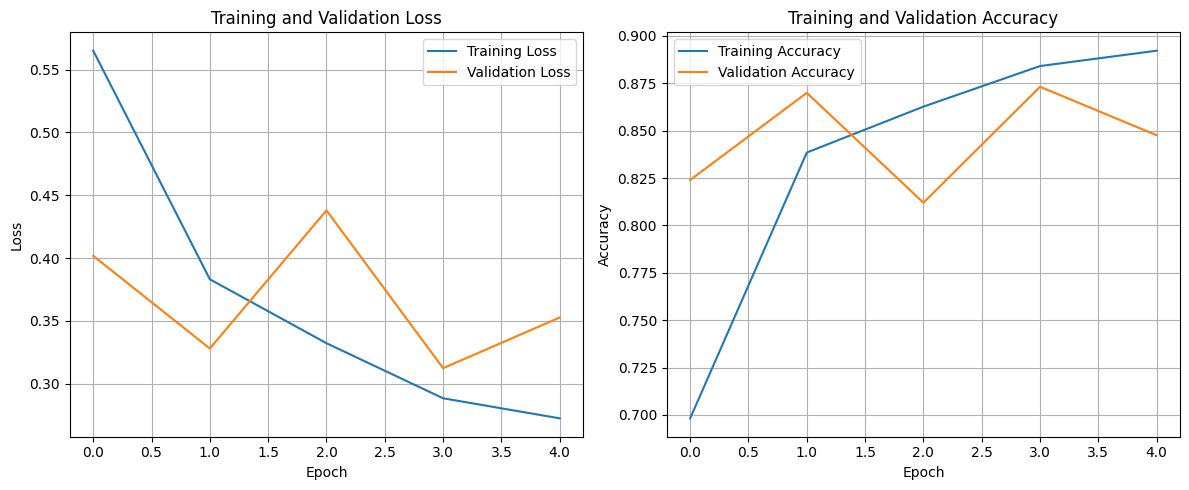

In [43]:
plt.figure(figsize=(12, 5))

# Loss 折線圖
plt.subplot(1, 2, 1)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()

# Accuracy 折線圖
plt.subplot(1, 2, 2)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

#使用全部測試資料評估準確率

In [44]:
scores = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("測試資料 Loss：", scores[0])
print("測試資料 Accuracy：", scores[1])

print("測試資料準確率：", scores[1] * 100, "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 56s 71ms/step - accuracy: 0.8546 - loss: 0.3374
測試資料 Loss： 0.33740106225013733
測試資料 Accuracy： 0.8545600175857544
測試資料準確率： 85.45600175857544 %


#儲存模型、權重與 Tokenizer

In [45]:
import json

# 儲存完整模型
model.save("IMDb_RNN_Model.keras")

# 儲存模型權重
model.save_weights("IMDb_RNN_Weights.weights.h5")

# 儲存 Tokenizer
tokenizer_json = token.to_json()

with open("IMDb_Tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer_json)

print("模型、權重及 Tokenizer 儲存完成！")

模型、權重及 Tokenizer 儲存完成！
